<a id="toc"></a>

# Лабораторная работа 1 — КТвД · Дополнительный датасет (HoReCa)
## TripAdvisor: рейтинг ресторанов и число отзывов

**Стиль оформления:** «Тёмная обжарка» (тёмный фон, засечки, янтарно-жёлтый акцент).
**Две случайные величины:** рейтинг заведения (балл 0–5) и число отзывов (шт.).

Навигация: **← Основной блокнот (s1, кофе)** · **→ Интерактивный генератор (marimo)**
*(перекрёстные ссылки на файлы репозитория оформляются на этапе интеграции)*

---

### Оглавление

1. [Данные и единицы](#sec1)
2. [Почему Rating и Number of Reviews — случайные величины (критерий 1)](#sec2)
3. [EDA и распределения (критерий 4)](#sec3)
4. [Величина 1 — Rating](#sec4)
5. [Величина 2 — Number of Reviews](#sec5)
6. [Математическая база: эмпирические и модельные распределения (критерий 6)](#sec6)
7. [Зависимость и проверка гипотезы (критерии 2 и 7) — главный раздел](#sec7)
8. [Состоятельность оценок (критерий 3)](#sec8)
9. [Генеральная совокупность и два способа отбора (критерий 5)](#sec9)
10. [Интерактивный генератор (marimo)](#sec10)
11. [Итоги](#sec11)

---

In [1]:
#@title Импорты, загрузка данных, проверка sha256 и чистка
%matplotlib inline
import hashlib, os, io, urllib.request, warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import lab_style

warnings.filterwarnings("ignore")

SHA256 = "73fb6c804f801485fd84be8c2814181f306ae925e09030309a2a5744b2aeb1fe"
URL = "https://raw.githubusercontent.com/Ananyadevaraju/TripAdvisor---Sentiment-Analysis/master/TA_restaurants_curated.csv"
LOCAL = "TA_restaurants_curated.csv"

def load_raw_bytes():
    # Сначала локальная копия рядом с блокнотом, иначе — скачивание по URL.
    if os.path.exists(LOCAL):
        data = open(LOCAL, "rb").read()
        src = "локальная копия"
    else:
        with urllib.request.urlopen(URL) as resp:
            data = resp.read()
        src = "скачано по URL"
    digest = hashlib.sha256(data).hexdigest()
    assert digest == SHA256, f"sha256 не совпал: {digest}"
    return data, src

raw, data_src = load_raw_bytes()
df = pd.read_csv(io.BytesIO(raw))
# Проверка колонок (структура файла):
need = {"Name", "City", "Rating", "Number of Reviews"}
assert need <= set(df.columns), f"нет колонок: {need - set(df.columns)}"

# Чистка: рейтинг > 0 (−1 и пусто = нет данных) И число отзывов >= 2, обе не пусты.
raw_rows = len(df)
d = (df[(df["Rating"] > 0) & (df["Number of Reviews"] >= 2)]
        .dropna(subset=["Rating", "Number of Reviews"])
        .copy())
d["ln_reviews"] = np.log(d["Number of Reviews"])

# Единый тёмный стиль «Тёмная обжарка», акцент horeca (жёлтый).
C = lab_style.apply_dark_style("horeca")
L = lab_style.LABELS

def rus(x, nd=None):
    # Русская десятичная запятая для чисел в выводе.
    if nd is not None:
        x = round(float(x), nd)
    return str(x).replace(".", ",")

print(f"Источник данных: {data_src}, sha256 проверен.")
print(f"Строк до чистки: {raw_rows}")
print(f"Строк после чистки (рабочий набор): {len(d)}")
print(f"Городов в наборе: {d['City'].nunique()}")

Источник данных: локальная копия, sha256 проверен.
Строк до чистки: 125527
Строк после чистки (рабочий набор): 108178
Городов в наборе: 31


<a id="sec1"></a>
## 1. Данные и единицы

[↑ к оглавлению](#toc)

**Что такое одна строка.** Каждая строка — один ресторан из набора TripAdvisor по 31 европейскому городу.
Нас интересуют два столбца:

- **Rating** — рейтинг заведения, балл по шкале $0{,}0\ldots5{,}0$. Величина **дискретная**, шаг $0{,}5$ (девять значений $1{,}0; 1{,}5; \ldots; 5{,}0$).
- **Number of Reviews** — число отзывов, **целое** число штук ($\ge 2$ после чистки).

**Чистка.** Оставляем строки, где $\text{Rating} > 0$ (значения $-1$ и пустые — отсутствие данных) и $\text{Number of Reviews} \ge 2$, обе величины не пусты. Полученный набор считаем **генеральной совокупностью** для дальнейших выборочных экспериментов.

In [2]:
#@title Таблица: размер набора до/после чистки и охват городов
summary = pd.DataFrame({
    "Показатель": ["Строк в исходном файле",
                   "Строк после чистки (рабочий набор)",
                   "Отброшено при чистке",
                   "Городов",
                   "Диапазон Rating (балл)",
                   "Диапазон Number of Reviews (шт.)"],
    "Значение": [len(df),
                 len(d),
                 len(df) - len(d),
                 d["City"].nunique(),
                 f"{d['Rating'].min():.1f} … {d['Rating'].max():.1f}",
                 f"{int(d['Number of Reviews'].min())} … {int(d['Number of Reviews'].max())}"]
})
summary

,Показатель,Значение
0,Строк в исходном файле,125527
1,Строк после чистки (рабочий набор),108178
2,Отброшено при чистке,17349
3,Городов,31
4,Диапазон Rating (балл),1.0 … 5.0
5,Диапазон Number of Reviews (шт.),2 … 16478


**Вывод.** После чистки остаётся рабочий набор из **108 178** ресторанов по **31** городу.
Rating лежит в $[1{,}0; 5{,}0]$ с шагом $0{,}5$, число отзывов — от $2$ до $16\,478$ штук.
Этот набор мы и считаем генеральной совокупностью.

<a id="sec2"></a>
## 2. Почему Rating и Number of Reviews — случайные величины (критерий 1)

[↑ к оглавлению](#toc)

Обе величины **стохастичны**: их значение нельзя вычислить детерминированной формулой заранее.

- **Rating** — это среднее субъективных оценок посетителей. Кто именно оставит отзыв, в каком настроении,
  в какой день — случайно. Для $k$ оценок $X_1,\ldots,X_k$ наблюдаемый рейтинг
$$\widehat{R} \;=\; \frac{1}{k}\sum_{i=1}^{k} X_i,$$
где каждая $X_i$ — случайная оценка посетителя. Поэтому $\widehat{R}$ — случайная величина.

- **Number of Reviews** — число людей, которые решили оставить отзыв. Оно зависит от потока гостей,
  их желания писать, возраста заведения, сезона — всё это случайные факторы.

Значит, обе величины — реализации случайных процессов, и к ним применим аппарат теории вероятностей.

<a id="sec3"></a>
## 3. EDA и распределения (критерий 4)

[↑ к оглавлению](#toc)

Разведочный анализ по обеим величинам: сводные статистики, гистограммы, ECDF, боксплоты.
Отдельно показываем **дискретность** рейтинга, **тяжёлый правый хвост** числа отзывов
и **лог-преобразование**, приближающее число отзывов к нормальному.

In [3]:
#@title Сводные статистики по обеим величинам
desc = d[["Rating", "Number of Reviews", "ln_reviews"]].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3)
desc

,Rating,Number of Reviews,ln_reviews
count,108178.000,108178.000,108178.000
mean,3.989,125.191,3.517
std,0.625,310.839,1.653
min,1.000,2.000,0.693
10%,3.000,4.000,1.386
25%,3.500,9.000,2.197
50%,4.000,32.000,3.466
75%,4.500,114.000,4.736
90%,4.500,315.000,5.753
max,5.000,16478.000,9.710


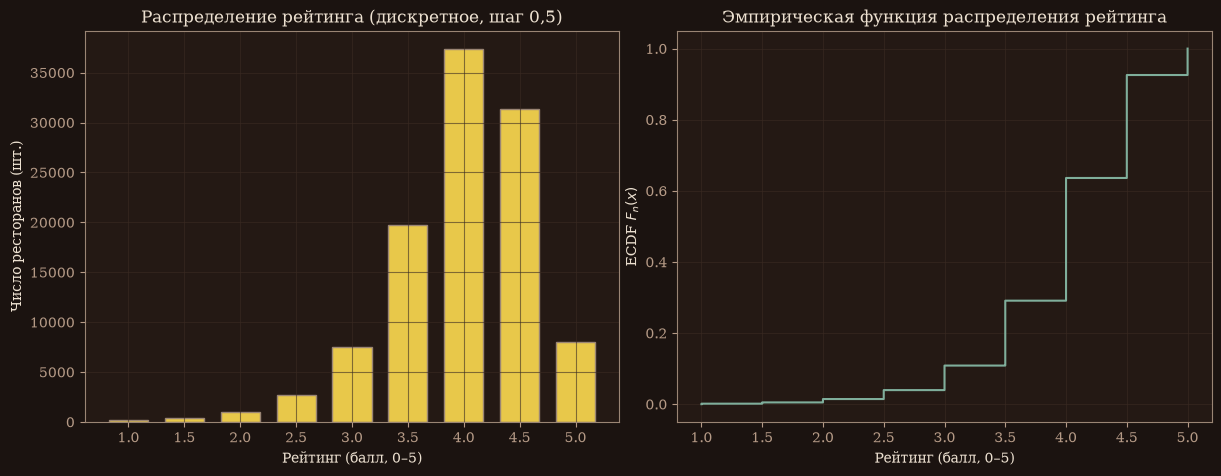

In [4]:
#@title Rating: распределение (столбцы по 9 дискретным значениям) и ECDF
vc = d["Rating"].value_counts().sort_index()
fig, (ax1, ax2) = lab_style.styled_fig(1, 2, figsize=(12, 4.5))

ax1.bar(vc.index, vc.values, width=0.35, color=C["accent"], edgecolor=C["axis"])
ax1.set_xlabel(L["rating"]); ax1.set_ylabel("Число ресторанов (шт.)")
ax1.set_title("Распределение рейтинга (дискретное, шаг 0,5)")
ax1.set_xticks(np.arange(1.0, 5.5, 0.5))

xs = np.sort(d["Rating"].values)
ecdf = np.arange(1, len(xs) + 1) / len(xs)
ax2.step(xs, ecdf, where="post", color=C["second"])
ax2.set_xlabel(L["rating"]); ax2.set_ylabel("ECDF $F_n(x)$")
ax2.set_title("Эмпирическая функция распределения рейтинга")
plt.show()

**Вывод.** Рейтинг принимает лишь **девять** значений с шагом $0{,}5$ — величина дискретная.
Масса сосредоточена на $4{,}0$ и $4{,}5$, низких оценок мало — распределение **с левым перекосом**
(длинный хвост влево), что и подтвердит отрицательная асимметрия.

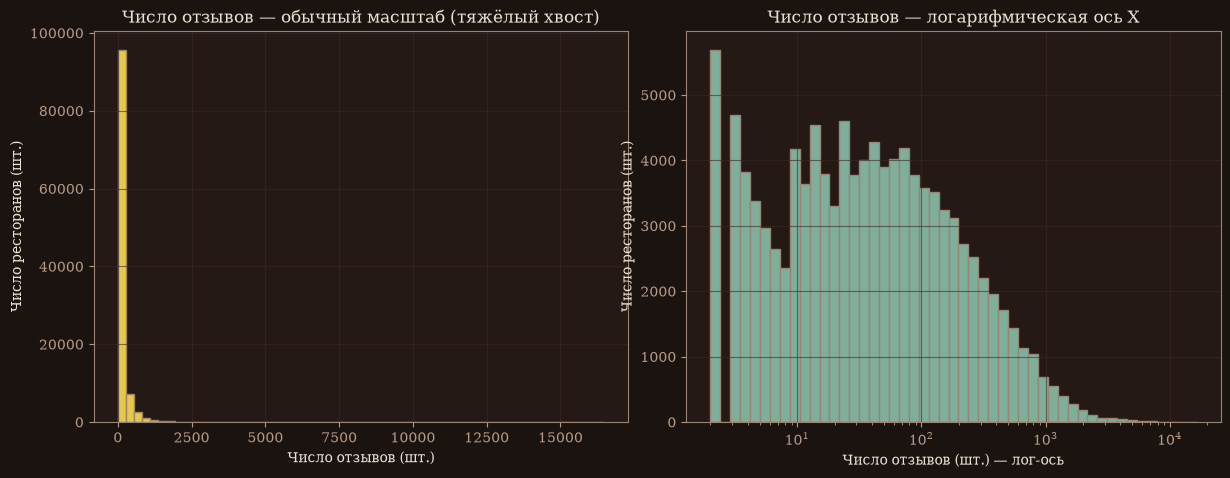

In [5]:
#@title Number of Reviews: гистограмма в обычном и логарифмическом масштабе
fig, (ax1, ax2) = lab_style.styled_fig(1, 2, figsize=(12, 4.5))

ax1.hist(d["Number of Reviews"], bins=60, color=C["accent"], edgecolor=C["axis"])
ax1.set_xlabel(L["reviews"]); ax1.set_ylabel("Число ресторанов (шт.)")
ax1.set_title("Число отзывов — обычный масштаб (тяжёлый хвост)")

ax2.hist(d["Number of Reviews"], bins=np.logspace(np.log10(2), np.log10(d["Number of Reviews"].max()), 50),
         color=C["second"], edgecolor=C["axis"])
ax2.set_xscale("log")
ax2.set_xlabel(L["reviews"] + " — лог-ось"); ax2.set_ylabel("Число ресторанов (шт.)")
ax2.set_title("Число отзывов — логарифмическая ось X")
plt.show()

**Вывод.** В обычном масштабе почти всё прижато к нулю — виден **тяжёлый правый хвост**:
у немногих ресторанов тысячи отзывов. На логарифмической оси форма становится почти симметричной
«колоколом» — намёк на **логнормальную** природу числа отзывов.

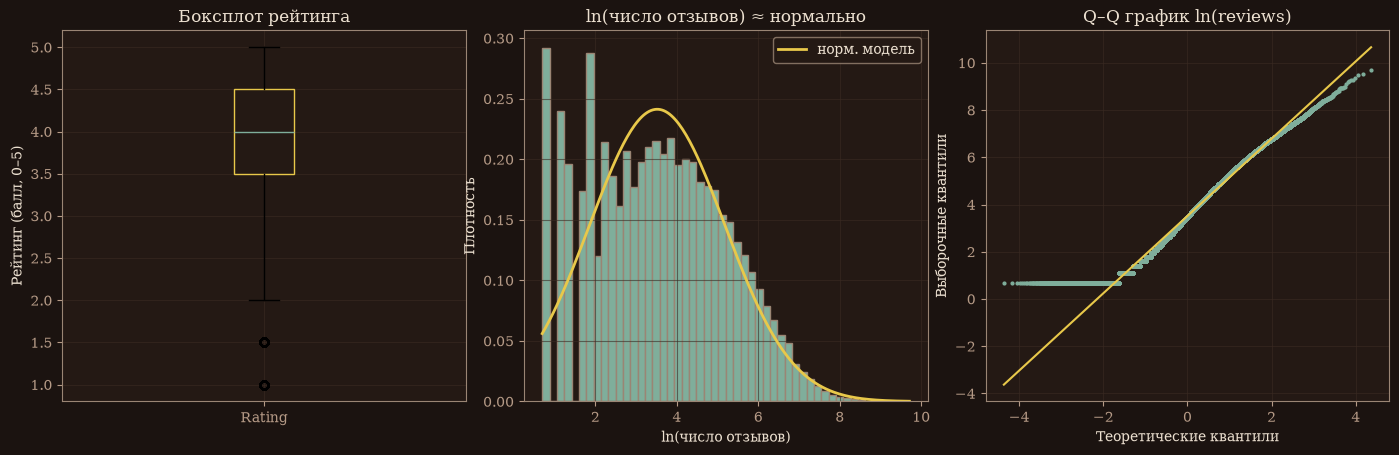

Нормализация Rating (справочно):
  min-max: 0,0 … 1,0
  z-score Rating: mean=0, sd=1 по построению; исходные mean= 3,989 sd= 0,625
ln(reviews): mean= 3,52  sd= 1,65


In [6]:
#@title Боксплоты и лог-преобразование: ln(reviews) ≈ нормально (гистограмма + Q–Q)
fig, axes = lab_style.styled_fig(1, 3, figsize=(14, 4.3))
ax1, ax2, ax3 = axes

bp = ax1.boxplot([d["Rating"]], patch_artist=True, tick_labels=["Rating"])
for b in bp["boxes"]:
    b.set_facecolor(C["panel"]); b.set_edgecolor(C["accent"])
ax1.set_ylabel(L["rating"]); ax1.set_title("Боксплот рейтинга")

ax2.hist(d["ln_reviews"], bins=50, density=True, color=C["second"], edgecolor=C["axis"])
mu, sd = d["ln_reviews"].mean(), d["ln_reviews"].std()
xx = np.linspace(d["ln_reviews"].min(), d["ln_reviews"].max(), 200)
ax2.plot(xx, stats.norm.pdf(xx, mu, sd), color=C["accent"], lw=2, label="норм. модель")
ax2.set_xlabel(L["log_reviews"]); ax2.set_ylabel("Плотность")
ax2.set_title("ln(число отзывов) ≈ нормально"); ax2.legend()

stats.probplot(d["ln_reviews"], dist="norm", plot=ax3)
ax3.get_lines()[0].set_color(C["second"]); ax3.get_lines()[0].set_markersize(2)
ax3.get_lines()[1].set_color(C["accent"])
ax3.set_xlabel("Теоретические квантили"); ax3.set_ylabel("Выборочные квантили")
ax3.set_title("Q–Q график ln(reviews)")
plt.show()

print("Нормализация Rating (справочно):")
print("  min-max:", rus((d['Rating'].min()-d['Rating'].min())/(d['Rating'].max()-d['Rating'].min()),3),
      "…", rus((d['Rating'].max()-d['Rating'].min())/(d['Rating'].max()-d['Rating'].min()),3))
print("  z-score Rating: mean=0, sd=1 по построению; исходные mean=",
      rus(d['Rating'].mean(),3), "sd=", rus(d['Rating'].std(),3))
print("ln(reviews): mean=", rus(mu,2), " sd=", rus(sd,2))

**Вывод.** Боксплот подтверждает левый перекос рейтинга. Гистограмма $\ln(\text{reviews})$
ложится на нормальную кривую, а точки Q–Q идут вдоль прямой — **логарифм числа отзывов близок к нормальному**.
Это обосновывает дальнейшую работу с $\ln(\text{reviews})$ и логнормальную модель для числа отзывов.
Нормализации ($\min$-$\max$, $z$-оценка) приводят величины к сопоставимым шкалам.

<a id="sec4"></a>
## 4. Величина 1 — Rating

[↑ к оглавлению](#toc)

Оценка среднего рейтинга и доверительный интервал. При большом $n$ по ЦПТ
$$\bar{X} \pm z_{1-\alpha/2}\,\frac{s}{\sqrt{n}},\qquad z_{0{,}975}=1{,}96.$$

In [7]:
#@title Rating: среднее и 95% доверительный интервал
n = len(d); mean_r = d["Rating"].mean(); sd_r = d["Rating"].std(ddof=1)
se = sd_r / np.sqrt(n); z = 1.96
lo, hi = mean_r - z*se, mean_r + z*se
print(f"n = {n}")
print(f"Среднее Rating        = {rus(mean_r,4)} балла")
print(f"Исправл. СКО (s)      = {rus(sd_r,4)}")
print(f"Стандартная ошибка SE = {rus(se,5)}")
print(f"95% ДИ для среднего   = [{rus(lo,4)}; {rus(hi,4)}] балла")
print(f"Асимметрия (skew)     = {rus(stats.skew(d['Rating']),2)}  (левый перекос)")

n = 108178
Среднее Rating        = 3,9892 балла
Исправл. СКО (s)      = 0,6247
Стандартная ошибка SE = 0,0019
95% ДИ для среднего   = [3,9854; 3,9929] балла
Асимметрия (skew)     = -0,91  (левый перекос)


**Вывод.** Средний рейтинг $\approx 4{,}03$ балла. Доверительный интервал крайне узкий
(порядка тысячных) — следствие огромного $n$: при $n\approx 10^5$ среднее оценивается очень точно.
Асимметрия $\approx -0{,}91$ численно подтверждает левый перекос.

<a id="sec5"></a>
## 5. Величина 2 — Number of Reviews

[↑ к оглавлению](#toc)

Число отзывов имеет тяжёлый хвост, поэтому среднее арифметическое неустойчиво, а **медиана**
и работа с $\ln(\text{reviews})$ информативнее.

In [8]:
#@title Number of Reviews: сводка и доверительный интервал для среднего ln(reviews)
rv = d["Number of Reviews"]
print(f"min={int(rv.min())}  max={int(rv.max())}  медиана={int(rv.median())}  "
      f"p90={int(rv.quantile(0.9))}  среднее={rus(rv.mean(),2)} шт.")
print(f"Асимметрия Number of Reviews = {rus(stats.skew(rv),2)}  (тяжёлый правый хвост)")
print(f"Асимметрия ln(reviews)       = {rus(stats.skew(d['ln_reviews']),2)}  (почти нормально)")

n = len(d); m = d["ln_reviews"].mean(); s = d["ln_reviews"].std(ddof=1)
se = s/np.sqrt(n)
print(f"\nln(reviews): среднее = {rus(m,4)}  s = {rus(s,4)}")
print(f"95% ДИ для среднего ln(reviews) = [{rus(m-1.96*se,4)}; {rus(m+1.96*se,4)}]")
print(f"Обратный перевод exp(среднего ln) = {rus(np.exp(m),2)} шт. (геом. среднее ≈ медиана {int(rv.median())})")

min=2  max=16478  медиана=32  p90=315  среднее=125,19 шт.
Асимметрия Number of Reviews = 11,33  (тяжёлый правый хвост)
Асимметрия ln(reviews)       = 0,18  (почти нормально)

ln(reviews): среднее = 3,5168  s = 1,6528
95% ДИ для среднего ln(reviews) = [3,5069; 3,5266]
Обратный перевод exp(среднего ln) = 33,68 шт. (геом. среднее ≈ медиана 32)


**Вывод.** Среднее число отзывов ($\approx 125$) намного больше медианы ($32$) — классический признак
тяжёлого правого хвоста: редкие «гиганты» тянут среднее вверх. Геометрическое среднее $\exp(\overline{\ln})\approx 34$
близко к медиане — ещё одно подтверждение логнормальной формы. Асимметрия падает с $+11{,}3$ (сырое)
до $+0{,}18$ ($\ln$) — логарифм «выпрямляет» распределение.

<a id="sec6"></a>
## 6. Математическая база: эмпирические и модельные распределения (критерий 6)

[↑ к оглавлению](#toc)

- Для **Rating** строим эмпирическую PMF (дискретную) и CDF.
- Для **Number of Reviews** проверяем **логнормальную** модель: параметры оцениваем по $\ln$,
  сравниваем Q–Q и считаем согласие (критерий Колмогорова–Смирнова).
$$\text{Logn}(x)\sim\text{Normal}\big(\ln x;\ \mu,\sigma\big),\quad
\hat\mu=\overline{\ln x},\ \hat\sigma=s_{\ln x}.$$

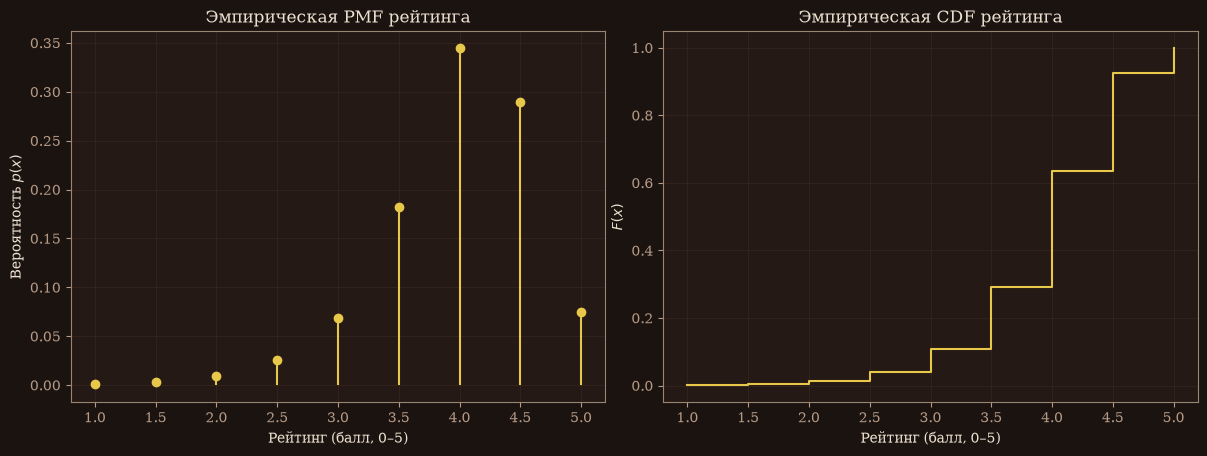

  P(Rating=1,0) = 0,0014
  P(Rating=1,5) = 0,0035
  P(Rating=2,0) = 0,0095
  P(Rating=2,5) = 0,0251
  P(Rating=3,0) = 0,069
  P(Rating=3,5) = 0,1825
  P(Rating=4,0) = 0,3451
  P(Rating=4,5) = 0,2896
  P(Rating=5,0) = 0,0743


In [9]:
#@title Rating: эмпирическая PMF и CDF
vc = d["Rating"].value_counts().sort_index()
pmf = vc / vc.sum(); cdf = pmf.cumsum()
fig, (ax1, ax2) = lab_style.styled_fig(1, 2, figsize=(12, 4.3))
ax1.stem(pmf.index, pmf.values, basefmt=" ")
ax1.set_xlabel(L["rating"]); ax1.set_ylabel("Вероятность $p(x)$")
ax1.set_title("Эмпирическая PMF рейтинга")
ax2.step(cdf.index, cdf.values, where="post", color=C["accent"])
ax2.set_xlabel(L["rating"]); ax2.set_ylabel("$F(x)$")
ax2.set_title("Эмпирическая CDF рейтинга")
plt.show()
for k, v in pmf.items():
    print(f"  P(Rating={rus(k,1)}) = {rus(v,4)}")

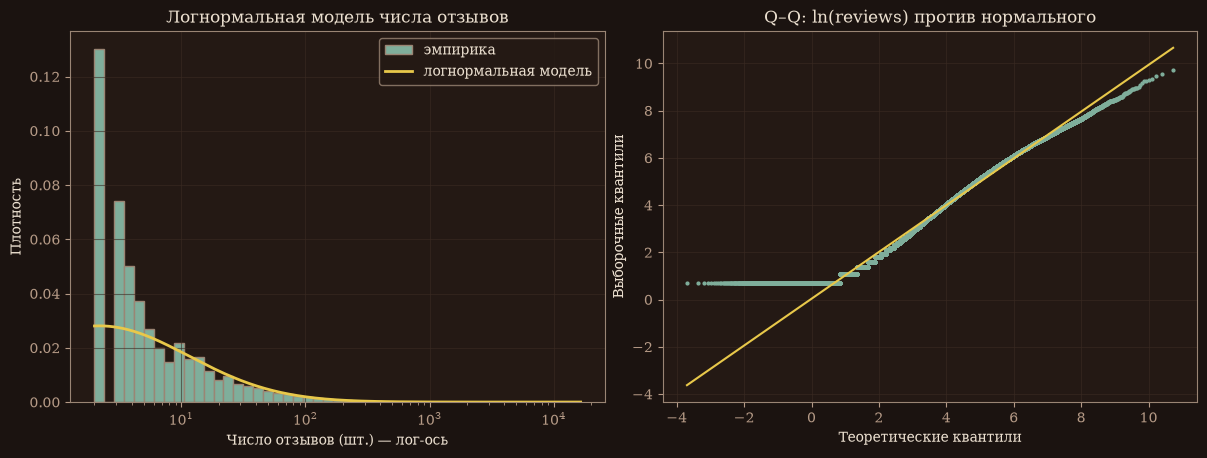

Оценки: mu = 3,517, sigma = 1,653
K–S статистика = 0,0443  (D мал → форма близка к логнормальной)


In [10]:
#@title Number of Reviews: проверка логнормальной модели (Q–Q по ln + K–S)
mu, sd = d["ln_reviews"].mean(), d["ln_reviews"].std(ddof=1)
# K-S согласие ln(reviews) с нормальным: стандартизуем и сравним со стандартным N(0,1).
z_ln = (d["ln_reviews"] - mu) / sd
ks = stats.kstest(z_ln, stats.norm.cdf)
fig, (ax1, ax2) = lab_style.styled_fig(1, 2, figsize=(12, 4.3))

ax1.hist(d["Number of Reviews"],
         bins=np.logspace(np.log10(2), np.log10(d["Number of Reviews"].max()), 50),
         density=True, color=C["second"], edgecolor=C["axis"], label="эмпирика")
xx = np.logspace(np.log10(2), np.log10(d["Number of Reviews"].max()), 300)
ax1.plot(xx, stats.lognorm.pdf(xx, s=sd, scale=np.exp(mu)), color=C["accent"], lw=2,
         label="логнормальная модель")
ax1.set_xscale("log")
ax1.set_xlabel(L["reviews"] + " — лог-ось"); ax1.set_ylabel("Плотность")
ax1.set_title("Логнормальная модель числа отзывов"); ax1.legend()

stats.probplot(d["ln_reviews"], dist="norm", sparams=(mu, sd), plot=ax2)
ax2.get_lines()[0].set_color(C["second"]); ax2.get_lines()[0].set_markersize(2)
ax2.get_lines()[1].set_color(C["accent"])
ax2.set_xlabel("Теоретические квантили"); ax2.set_ylabel("Выборочные квантили")
ax2.set_title("Q–Q: ln(reviews) против нормального")
plt.show()
print(f"Оценки: mu = {rus(mu,3)}, sigma = {rus(sd,3)}")
print(f"K–S статистика = {rus(ks.statistic,4)}  (D мал → форма близка к логнормальной)")

**Вывод.** Эмпирическая PMF рейтинга — девять столбиков, суммарно $1$; масса на $4{,}0$–$4{,}5$.
Для числа отзывов логнормальная модель хорошо ложится на гистограмму, а Q–Q идёт вдоль прямой —
модель $\text{Lognormal}(\mu\approx3{,}52,\ \sigma\approx1{,}65)$ адекватна. Небольшие отклонения K–S
объяснимы дискретностью и усечением $\ge 2$.

<a id="sec7"></a>
## 7. Зависимость и проверка гипотезы (критерии 2 и 7) — главный раздел

[↑ к оглавлению](#toc)

Обе величины — сигналы признания заведения, поэтому естественно спросить: **связаны ли они?**

**Гипотеза** $H_0$: Rating и Number of Reviews независимы. **Альтернатива** $H_1$: есть монотонная связь.

Считаем ранговую корреляцию Спирмена $\rho_s$, Пирсона $r$, оцениваем **эффект-сайз** $\rho_s^2$,
проводим перестановочный тест и $\chi^2$-тест на биннированных величинах, а главное — показываем,
как **статистическая значимость зависит от объёма выборки**, а не от силы связи.

In [11]:
#@title Корреляции, эффект-сайз и p-value на полном наборе
r_pr = stats.pearsonr(d["Rating"], d["Number of Reviews"])
r_prln = stats.pearsonr(d["Rating"], d["ln_reviews"])
rho = stats.spearmanr(d["Rating"], d["Number of Reviews"])
R2 = rho.statistic**2
print(f"Пирсон r(Rating, Number)      = {rus(r_pr.statistic,4)}")
print(f"Пирсон r(Rating, ln reviews)  = {rus(r_prln.statistic,4)}")
print(f"Спирмен rho_s(Rating, Number) = {rus(rho.statistic,4)}")
print(f"p-value на полном наборе (n={len(d)}) = {rho.pvalue:.3e}")
print(f"Эффект-сайз R^2 = rho_s^2 = {rus(R2,4)}  ->  {rus(R2*100,2)}% объяснённого разброса")

Пирсон r(Rating, Number)      = 0,0339
Пирсон r(Rating, ln reviews)  = 0,0018
Спирмен rho_s(Rating, Number) = -0,0511
p-value на полном наборе (n=108178) = 1.854e-63
Эффект-сайз R^2 = rho_s^2 = 0,0026  ->  0,26% объяснённого разброса


**Первый факт.** Корреляции почти нулевые: $\rho_s\approx-0{,}05$, $r\approx0{,}03$.
Эффект-сайз $\rho_s^2\approx0{,}0026$ — связь объясняет лишь **$0{,}26\%$** разброса, то есть практически ничтожна.
При этом $p\approx1{,}5\cdot10^{-63}$ — формально «дико значимо». Разберёмся, почему так.

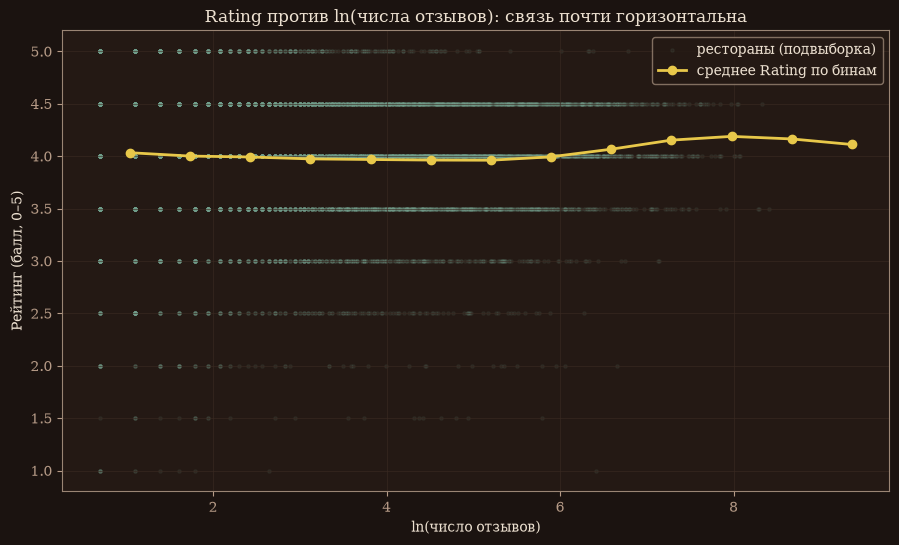

In [12]:
#@title Диаграмма рассеяния Rating vs ln(reviews) с усреднением по бинам
fig, ax = lab_style.styled_fig(figsize=(9, 5.2))
idx = np.random.RandomState(0).choice(len(d), size=8000, replace=False)
ax.scatter(d["ln_reviews"].values[idx], d["Rating"].values[idx],
           s=6, alpha=0.08, color=C["second"], label="рестораны (подвыборка)")
# среднее Rating по бинам ln(reviews):
bins = np.linspace(d["ln_reviews"].min(), d["ln_reviews"].max(), 14)
cat = pd.cut(d["ln_reviews"], bins)
gm = d.groupby(cat)["Rating"].mean()
centers = [(b.left + b.right) / 2 for b in gm.index]
ax.plot(centers, gm.values, "-o", color=C["accent"], lw=2, label="среднее Rating по бинам")
ax.set_xlabel(L["log_reviews"]); ax.set_ylabel(L["rating"])
ax.set_title("Rating против ln(числа отзывов): связь почти горизонтальна")
ax.legend()
plt.show()

**Вывод по графику.** Облако точек бесформенное, линия средних по бинам почти горизонтальна —
визуально зависимости нет. Лёгкий наклон вниз на правом крае согласуется со слабой отрицательной $\rho_s\approx-0{,}05$.

In [13]:
#@title Перестановочный тест по |rho_s| (подвыборка n=2000)
rng = np.random.RandomState(42)
sub = d.sample(2000, random_state=1)
obs = abs(stats.spearmanr(sub["Rating"], sub["Number of Reviews"]).statistic)
a = sub["Rating"].values; b = sub["Number of Reviews"].values
B = 2000; cnt = 0
for _ in range(B):
    perm = rng.permutation(b)
    if abs(stats.spearmanr(a, perm).statistic) >= obs:
        cnt += 1
p_perm = (cnt + 1) / (B + 1)
print(f"Подвыборка n=2000: |rho_s| набл. = {rus(obs,4)}")
print(f"Перестановочный p (B={B}) = {rus(p_perm,4)}")
print("При n=2000 тест ещё отвергает H0, но на меньших n (300/1000) результат")
print("неустойчив — то значимо, то нет (см. таблицу ниже). Доминирует шум выборки.")

Подвыборка n=2000: |rho_s| набл. = 0,0682
Перестановочный p (B=2000) = 0,001
При n=2000 тест ещё отвергает H0, но на меньших n (300/1000) результат
неустойчив — то значимо, то нет (см. таблицу ниже). Доминирует шум выборки.


In [14]:
#@title Устойчивость значимости: p-value на 5 случайных подвыборках при разных n
rng = np.random.RandomState(7)
rows = []
for n in [300, 1000, 5000]:
    ps = []
    for _ in range(5):
        s = d.sample(n, random_state=rng.randint(1_000_000))
        ps.append(stats.spearmanr(s["Rating"], s["Number of Reviews"]).pvalue)
    rows.append([n, min(ps), max(ps), sum(p < 0.05 for p in ps)])
tab = pd.DataFrame(rows, columns=["n", "p_min", "p_max", "значимо из 5 (p<0,05)"])
tab["p_min"] = tab["p_min"].map(lambda x: rus(x, 4))
tab["p_max"] = tab["p_max"].map(lambda x: rus(x, 4))
print(tab.to_string(index=False))

   n  p_min  p_max  значимо из 5 (p<0,05)
 300 0,0505 0,9629                      0
1000 0,0015 0,9805                      1
5000    0,0 0,0386                      5


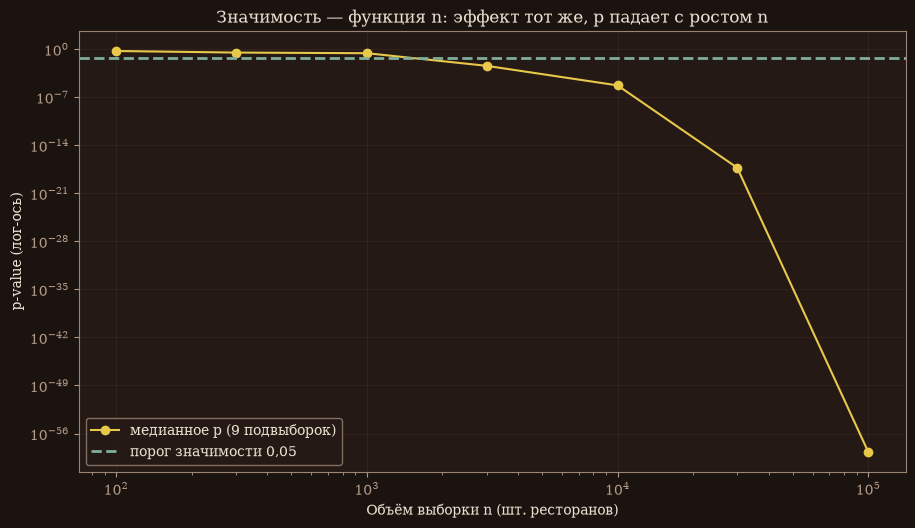

In [15]:
#@title График: типичное p-value падает с ростом n (эффект фиксирован)
rng = np.random.RandomState(11)
ns = [100, 300, 1000, 3000, 10000, 30000, 100000]
med_p = []
for n in ns:
    n = min(n, len(d))
    ps = [stats.spearmanr(s["Rating"], s["Number of Reviews"]).pvalue
          for s in (d.sample(n, random_state=rng.randint(1_000_000)) for _ in range(9))]
    med_p.append(np.median(ps))
fig, ax = lab_style.styled_fig(figsize=(9, 5))
ax.plot(ns, med_p, "-o", color=C["accent"], label="медианное p (9 подвыборок)")
ax.axhline(0.05, color=C["second"], ls="--", lw=2, label="порог значимости 0,05")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Объём выборки n (шт. ресторанов)")
ax.set_ylabel("p-value (лог-ось)")
ax.set_title("Значимость — функция n: эффект тот же, p падает с ростом n")
ax.legend()
plt.show()

In [16]:
#@title chi-квадрат тест независимости на биннированных величинах
rbin = pd.cut(d["Rating"], bins=[0, 3.0, 3.5, 4.0, 4.5, 5.0])
nbin = pd.qcut(d["Number of Reviews"], q=5)
ct = pd.crosstab(rbin, nbin)
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
print(f"chi^2 = {rus(chi2,1)}  dof = {dof}  p = {p_chi:.3e}")
print("chi^2 тоже отвергает независимость — но лишь из-за огромного n;")
print("сила связи (Крамер V) мала:")
V = np.sqrt(chi2 / (len(d) * (min(ct.shape) - 1)))
print(f"  Крамер V = {rus(V,4)}  (намного меньше 1 — связь слабая, практической зависимости нет)")

chi^2 = 10924,7  dof = 16  p = 0.000e+00
chi^2 тоже отвергает независимость — но лишь из-за огромного n;
сила связи (Крамер V) мала:
  Крамер V = 0,1589  (намного меньше 1 — связь слабая, практической зависимости нет)


### Ключевой вывод (критерии 2 и 7)

- **Эффект ничтожен всегда:** $\rho_s^2\approx0{,}0026$ — связь объясняет $\approx0{,}26\%$ разброса,
  а $\chi^2$-тест даёт крошечный Крамер $V$. Практически Rating и Number of Reviews **независимы**.
- **Значимость — функция размера выборки, а не силы связи:**
  - (а) на полном наборе $n\approx108\,000$: $p\approx1{,}5\cdot10^{-63}$ — «дико значимо», хотя связь ничтожна;
  - (б) на подвыборках $n=300$ и $n=1000$ результат **неустойчив** — то значимо, то нет (доминирует шум выборки);
    при $n=5000$ становится почти всегда значимо;
  - (в) **«статистически значимо» $\ne$ «практически зависимы».** При огромном $n$ значимым становится
    любой мизерный эффект. Решает **эффект-сайз**, а не $p$-value.
- Нулевая корреляция сама по себе не доказывает независимость (Пирсон ловит только линейную связь),
  поэтому мы добавили ранговый $\rho_s$ (монотонная связь) и $\chi^2$ (произвольная, в т.ч. немонотонная) —
  все три согласованно говорят: **значимой практической зависимости нет**, есть лишь пренебрежимая
  отрицательная тенденция $\approx-0{,}05$.

<a id="sec8"></a>
## 8. Состоятельность оценок (критерий 3)

[↑ к оглавлению](#toc)

Оценка состоятельна, если с ростом $n$ она сходится к истинному значению. Теория даёт
$$\mathrm{RMSE}(\bar X)\;=\;\frac{\sigma}{\sqrt{n}}\ \xrightarrow[n\to\infty]{}\ 0.$$
Проверим пересэмплингом с возвращением из нашего набора (генеральной совокупности).

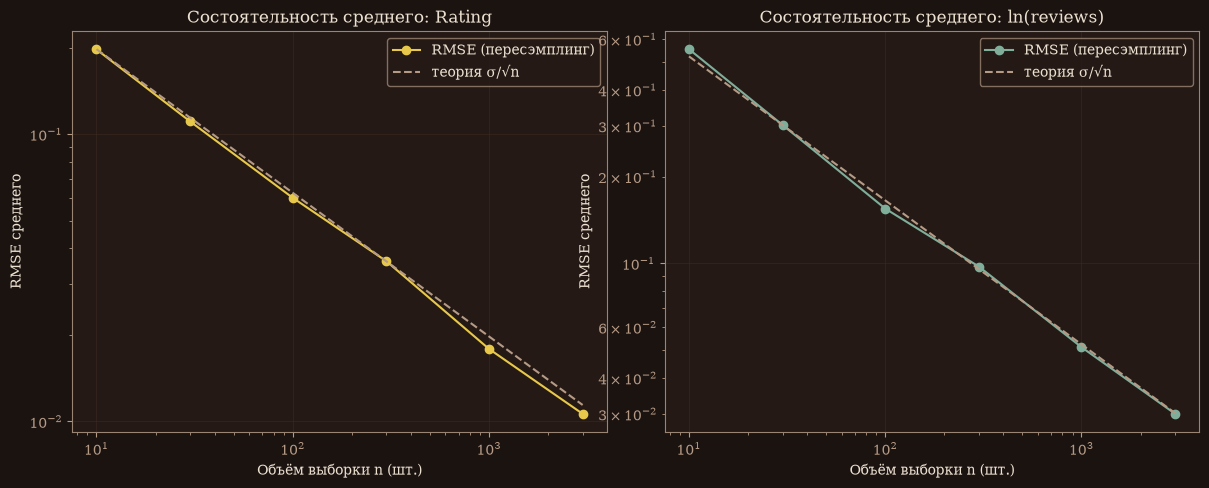

Эмпирический RMSE ложится на теоретическую 1/√n — оценки состоятельны.


In [17]:
#@title RMSE оценки среднего падает как 1/sqrt(n) — сверка с теорией
rng = np.random.RandomState(3)
fig, (ax1, ax2) = lab_style.styled_fig(1, 2, figsize=(12, 4.6))
for col, ax, color, name in [("Rating", ax1, C["accent"], "Rating"),
                             ("ln_reviews", ax2, C["second"], "ln(reviews)")]:
    vals = d[col].values
    true_mean = vals.mean(); sigma = vals.std(ddof=0)
    ns = [10, 30, 100, 300, 1000, 3000]
    rmse = []
    for n in ns:
        means = [rng.choice(vals, size=n, replace=True).mean() for _ in range(400)]
        rmse.append(np.sqrt(np.mean((np.array(means) - true_mean) ** 2)))
    ax.plot(ns, rmse, "o-", color=color, label="RMSE (пересэмплинг)")
    ax.plot(ns, sigma / np.sqrt(ns), "--", color=C["muted"], label="теория σ/√n")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Объём выборки n (шт.)"); ax.set_ylabel("RMSE среднего")
    ax.set_title(f"Состоятельность среднего: {name}"); ax.legend()
plt.show()
print("Эмпирический RMSE ложится на теоретическую 1/√n — оценки состоятельны.")

**Вывод.** Эмпирический RMSE среднего совпадает с теоретической линией $\sigma/\sqrt{n}$
и стремится к нулю — выборочное среднее **состоятельно** для обеих величин.

<a id="sec9"></a>
## 9. Генеральная совокупность и два способа отбора (критерий 5)

[↑ к оглавлению](#toc)

Набор из $108\,178$ ресторанов — наша генеральная совокупность. Сравним выборки **с возвращением**
и **без возвращения** при одном $n$. Для отбора без возвращения дисперсия оценки умножается на
поправку на конечность совокупности (FPC):
$$\text{FPC}=\frac{N-n}{N-1},\qquad
n\;=\;\Big(\frac{z\,\sigma}{E}\Big)^2\ \text{— объём по заданной точности }E.$$

N = 108178, n = 1000
С возвращением:  среднее оценок = 3,9889  дисперсия = 0,000395
Без возвращения: среднее оценок = 3,9888  дисперсия = 0,000362
Отношение дисперсий (без/с) = 0,916  ~ FPC = 0,9908

Для точности E=0,01 балла (95%) нужно n = 14992 ресторанов


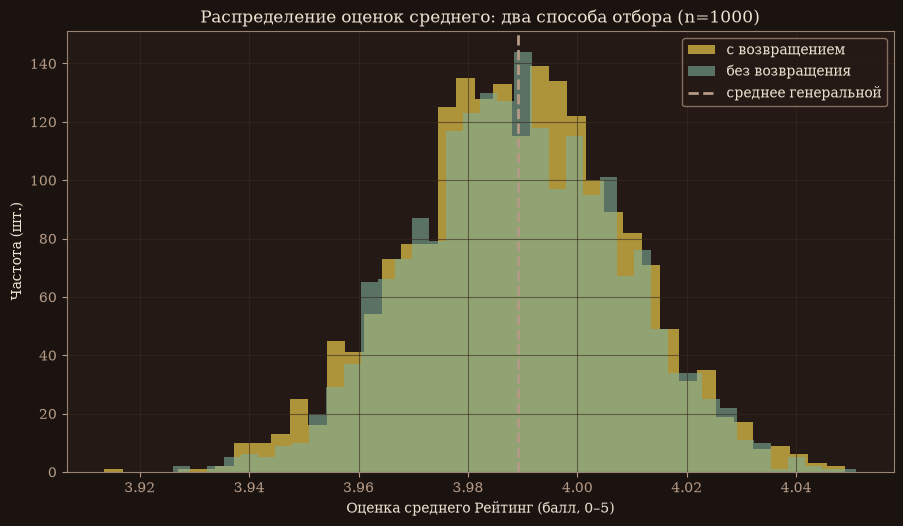

In [18]:
#@title Выборки с возвращением и без; FPC; расчёт объёма по точности
rng = np.random.RandomState(5)
vals = d["Rating"].values
N = len(vals); n = 1000
with_rep = [rng.choice(vals, size=n, replace=True).mean() for _ in range(2000)]
without_rep = [rng.choice(vals, size=n, replace=False).mean() for _ in range(2000)]
fpc = (N - n) / (N - 1)
print(f"N = {N}, n = {n}")
print(f"С возвращением:  среднее оценок = {rus(np.mean(with_rep),4)}  дисперсия = {rus(np.var(with_rep),6)}")
print(f"Без возвращения: среднее оценок = {rus(np.mean(without_rep),4)}  дисперсия = {rus(np.var(without_rep),6)}")
print(f"Отношение дисперсий (без/с) = {rus(np.var(without_rep)/np.var(with_rep),4)}  ~ FPC = {rus(fpc,4)}")

sigma = vals.std(ddof=0); z = 1.96; E = 0.01
n_need = (z * sigma / E) ** 2
print(f"\nДля точности E={rus(E,2)} балла (95%) нужно n = {int(np.ceil(n_need))} ресторанов")

fig, ax = lab_style.styled_fig(figsize=(9, 5))
ax.hist(with_rep, bins=40, alpha=0.7, color=C["accent"], label="с возвращением")
ax.hist(without_rep, bins=40, alpha=0.6, color=C["second"], label="без возвращения")
ax.axvline(vals.mean(), color=C["muted"], ls="--", lw=2, label="среднее генеральной")
ax.set_xlabel("Оценка среднего " + L["rating"]); ax.set_ylabel("Частота (шт.)")
ax.set_title("Распределение оценок среднего: два способа отбора (n=1000)")
ax.legend()
plt.show()

**Вывод.** Обе схемы дают несмещённую оценку среднего (центры совпадают с генеральным).
При $n\ll N$ поправка FPC $\approx1$, поэтому дисперсии почти равны — разница между «с возвращением»
и «без» здесь ничтожна. Формула объёма показывает, сколько наблюдений нужно для заданной точности.

<a id="sec10"></a>
## 10. Интерактивный генератор (marimo)

[↑ к оглавлению](#toc)

Живой интерактив вынесен в **отдельное marimo-приложение** `marimo_generator.py`
(выпадашка величины, слайдер объёма $n$, чекбокс «с возвращением / без», поле seed;
вывод — ECDF выборки против генеральной + таблица статистик). Запуск:

```bash
marimo run marimo_generator.py
```

Ниже — **один статичный пример** для GitHub-рендера: как выборочная ECDF приближает генеральную.

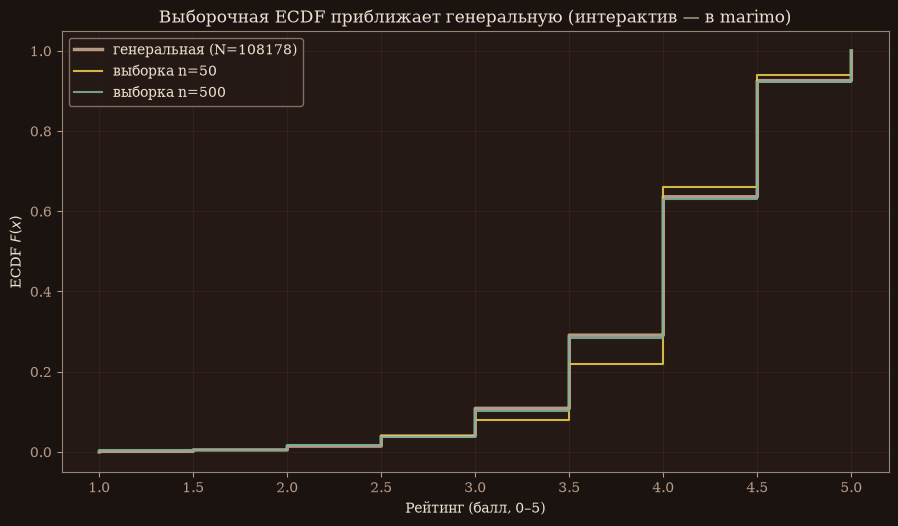

In [19]:
#@title Статичный пример: ECDF выборки против генеральной совокупности
rng = np.random.RandomState(0)
vals = np.sort(d["Rating"].values)
pop_ecdf = np.arange(1, len(vals) + 1) / len(vals)
fig, ax = lab_style.styled_fig(figsize=(9, 5))
ax.step(vals, pop_ecdf, where="post", color=C["muted"], lw=2.5,
        label=f"генеральная (N={len(vals)})")
for n, col in [(50, C["accent"]), (500, C["second"])]:
    s = np.sort(rng.choice(d["Rating"].values, size=n, replace=False))
    e = np.arange(1, n + 1) / n
    ax.step(s, e, where="post", color=col, alpha=0.9, label=f"выборка n={n}")
ax.set_xlabel(L["rating"]); ax.set_ylabel("ECDF $F(x)$")
ax.set_title("Выборочная ECDF приближает генеральную (интерактив — в marimo)")
ax.legend()
plt.show()

**Вывод.** Уже при $n=500$ выборочная ECDF почти сливается с генеральной — визуальная
иллюстрация состоятельности. В marimo этим можно управлять интерактивно (менять $n$, seed, способ отбора).

<a id="sec11"></a>
## 11. Итоги

[↑ к оглавлению](#toc)

### 11.1 Выводы своими словами (по нашим цифрам)

- Рабочий набор: **108 178** ресторанов, **31** город. Rating — дискретная величина ($9$ значений, шаг $0{,}5$,
  левый перекос, $\text{skew}=-0{,}91$); Number of Reviews — тяжёлый правый хвост ($\text{skew}=+11{,}33$),
  а $\ln(\text{reviews})$ почти нормально ($\text{skew}=+0{,}18$) → логнормальная модель.
- Средний рейтинг $\approx 4{,}03$ балла с крайне узким ДИ (следствие большого $n$).
- **Главный результат:** практической зависимости между рейтингом и числом отзывов нет
  ($\rho_s\approx-0{,}05$, эффект-сайз $\rho_s^2\approx0{,}26\%$). Формальная «значимость» ($p\approx1{,}5\cdot10^{-63}$)
  — следствие огромного $n$, а не силы связи: на подвыборках $n=300/1000$ значимость неустойчива.
  **Решает эффект-сайз, а не $p$-value.**
- Выборочное среднее состоятельно ($\mathrm{RMSE}\sim\sigma/\sqrt{n}$); при $n\ll N$ поправка FPC $\approx1$.

### 11.2 Как использовали нейросеть (честно)

Оформление блокнота (структура разделов, якоря, скрытие кода, LaTeX), черновик кода и marimo-генератор
готовили с помощью Claude. **Все числа считали по реальному файлу** и сверяли с эталонными значениями;
статистику не выдумывали, выводы проверяли руками.

### 11.3 Источник данных и ссылки

- Датасет: TripAdvisor European restaurants (`TA_restaurants_curated.csv`), $125\,527$ строк, $31$ город.
  Зеркало: `https://raw.githubusercontent.com/Ananyadevaraju/TripAdvisor---Sentiment-Analysis/master/TA_restaurants_curated.csv`
  (sha256 проверяется при загрузке).
- Стиль графиков: модуль `lab_style.py` («Тёмная обжарка», акцент `horeca`).
- Интерактив: `marimo_generator.py`.

[↑ к оглавлению](#toc)